In [20]:
pip install sqlalchemy psycopg2-binary

Note: you may need to restart the kernel to use updated packages.


In [21]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [40]:
import os
import pandas as pd
from sqlalchemy import create_engine, inspect
from dotenv import load_dotenv

#(.env file)
load_dotenv()

# The credentials
host = os.getenv("DB_HOST")
port = os.getenv("DB_PORT")
database = os.getenv("DB_NAME")
user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")

# Building the secure connection bridge
connection_string = f"postgresql://{user}:{password}@{host}:{port}/{database}"
engine = create_engine(connection_string)

try:
    inspector = inspect(engine)
    tables = inspector.get_table_names()
    print("Connection Successful! Tables available for analytics:")
    for table in tables:
        print(f"   - {table}")
except Exception as e:
    print(f"Connection failed. Check your .env file for typos. Error: {e}")

Connection Successful! Tables available for analytics:
   - property_listings


In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
query = "SELECT * FROM property_listings"

df = pd.read_sql(query, engine)
print(f"Success! Total records imported: {len(df)}")

Success! Total records imported: 2005


In [43]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
df [['price' , 'floor_size' , 'bedrooms' , 'bathrooms']].describe()

,price,floor_size,bedrooms,bathrooms
count,2005.00,1807.00,1940.00,1953.00
mean,32850690.85,193.09,2.56,3.00
std,50737695.70,329.85,1.39,1.87
min,3812.00,1.00,1.00,1.00
25%,9000000.00,72.00,1.00,1.00
50%,14600000.00,120.00,2.00,2.00
75%,27600000.00,213.00,4.00,5.00
max,600000000.00,4321.00,11.00,12.00


In [44]:
df['location'].value_counts()

location
Westlands          971
Kileleshwa         241
Kilimani           174
Riverside          152
Lavington           83
Karen               75
Runda               40
Kiambu Road         38
Syokimau            35
Spring Valley       22
Lower Kabete        20
Loresho             20
Parklands           19
Peponi              18
Upper Hill          18
Gigiri              11
Kerarapon           10
Kitisuru             7
Muthangari           6
Industrial Area      6
Ridgeways            4
Thigiri              4
Garden Estate        4
Joska                3
Mlolongo             3
South C              3
Muthaiga North       3
Mountain View        2
Githurai             2
Katani               2
Langata              2
Riruta               2
Kyuna                1
Rosslyn              1
Mombasa Rd           1
Dagoretti            1
Nyari                1
Name: count, dtype: int64

In [45]:
# Filter for properties with a ridiculously small floor size
df[df['floor_size'] < 10]

,id,title,price_raw,floor_size_raw,price,bedrooms,bathrooms,floor_size,location,constituency,address,excerpt,link,scraped_at,price_flag,floor_size_flag
1426,4375,1 Bedroom Apartment / Flat,KSh 8 300 000,1 m²,8300000.00,1.00,1.00,1.00,Riverside,Westlands,"Riverside Dr Nairobi, Riverside, Nairobi",???? A modern one bedroom unit is available ...,https://www.property24.co.ke/1-bedroom-apartme...,2026-06-16 12:47:03.343103,None,NaN
1480,5421,1 Bedroom Apartment / Flat,KSh 8 300 000,1 m²,8300000.00,1.00,1.00,1.00,Riverside,Westlands,"Riverside Dr Nairobi, Riverside, Nairobi",???? A modern one bedroom unit is available ...,https://www.property24.co.ke/1-bedroom-apartme...,2026-06-16 12:47:10.366302,None,NaN


In [46]:
# Filter for properties over 500 Million KSh
df[df['price'] >= 500000000]

,id,title,price_raw,floor_size_raw,price,bedrooms,bathrooms,floor_size,location,constituency,address,excerpt,link,scraped_at,price_flag,floor_size_flag
843,883,Vacant Land / Plot,KSh 600 000 000,N/A,600000000.00,NaN,NaN,NaN,Kileleshwa,Langata,"Kileleshwa Nairobi, Kileleshwa, Nairobi",A rare investment opportunity in the prestigio...,https://www.property24.co.ke/vacant-land-plot-...,2026-06-12 17:13:50.891436,None,NaN
1419,4297,6 Bedroom House,KSh 520 000 000,650 m²,520000000.00,6.00,7.00,650.00,Kitisuru,Westlands,"Kitisuru Nairobi, Kitisuru, Nairobi",Logo BuyRentKenya\r\nSale\r\nHouses\r\nNairobi...,https://www.property24.co.ke/6-bedroom-house-f...,2026-06-16 12:47:03.343103,None,NaN


In [47]:
# Filter for properties with more than 8 bedrooms
df[df['bedrooms'] > 8]

,id,title,price_raw,floor_size_raw,price,bedrooms,bathrooms,floor_size,location,constituency,address,excerpt,link,scraped_at,price_flag,floor_size_flag
140,181,11 Bedroom Townhouse,KSh 195 000 000,400 m²,195000000.00,11.00,12.00,400.00,Karen,Langata,"Karen Karen, Karen, Nairobi",?? Karen | 11-Bedroom Luxury Villa For Sale\r\...,https://www.property24.co.ke/11-bedroom-townho...,2026-06-12 17:13:50.891436,None,NaN
1687,7927,11 Bedroom Townhouse,KSh 195 000 000,400 m²,195000000.00,11.00,12.00,400.00,Karen,Langata,"Karen Karen, Karen, Nairobi",?? Karen | 11-Bedroom Luxury Villa For Sale\r\...,https://www.property24.co.ke/11-bedroom-townho...,2026-06-17 11:31:35.845600,None,NaN


In [48]:
# Data cleaning

# 1. Address Placeholder Values
# Convert the fake "1.0 sqm" floor sizes to standard missing values (NaN)
df['floor_size'] = df['floor_size'].replace(1.0, np.nan)

# 2. Filter Out Non-Residential Properties
# Remove any row where the title contains "Vacant Land"
df = df[~df['title'].str.contains('Vacant Land', case=False, na=False)]

# 3. Remove Duplicate Listings
# Drop rows that have the exact same title, price, location, and size
df = df.drop_duplicates(subset=['title', 'price', 'location', 'floor_size'])

# 4. Feature Engineering (KPI Creation)
# Calculate the Price per Square Meter for the dashboard
df['price_per_sqm'] = df['price'] / df['floor_size']

# Verify the final clean count
print(f"Cleaned dataset ready: {len(df)} properties")

Cleaned dataset ready: 676 properties


<Axes: >

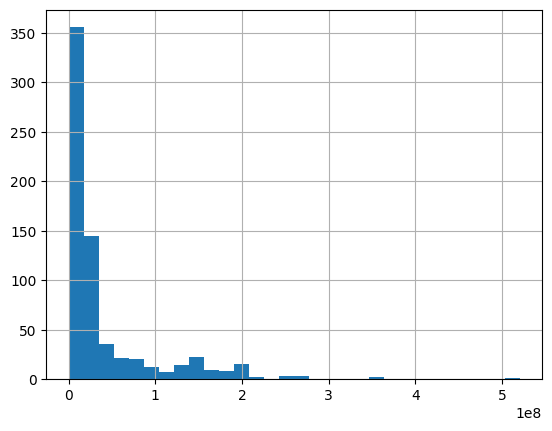

In [49]:
df['price'].hist(bins=30)

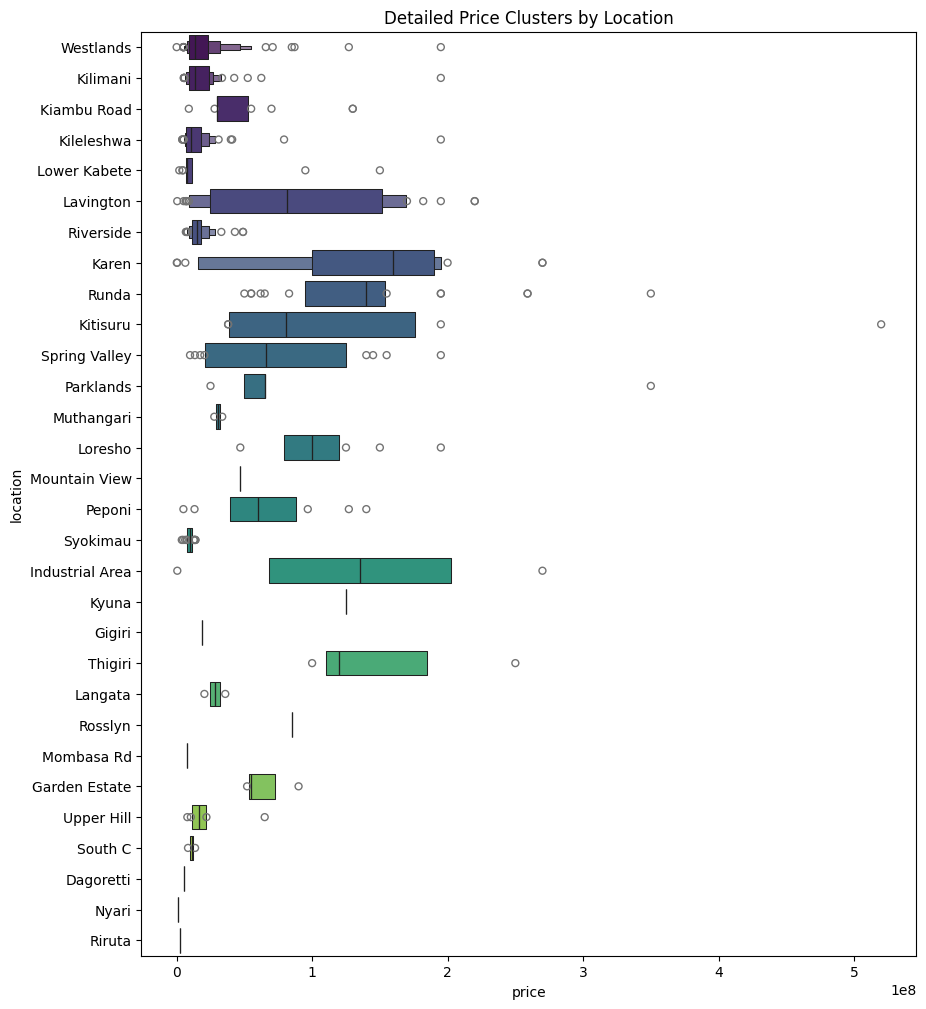

In [50]:
plt.figure(figsize=(10, 12))

sns.boxenplot(data=df, x='price', y='location', hue='location', palette='viridis', legend=False)
plt.title("Detailed Price Clusters by Location")
plt.show()

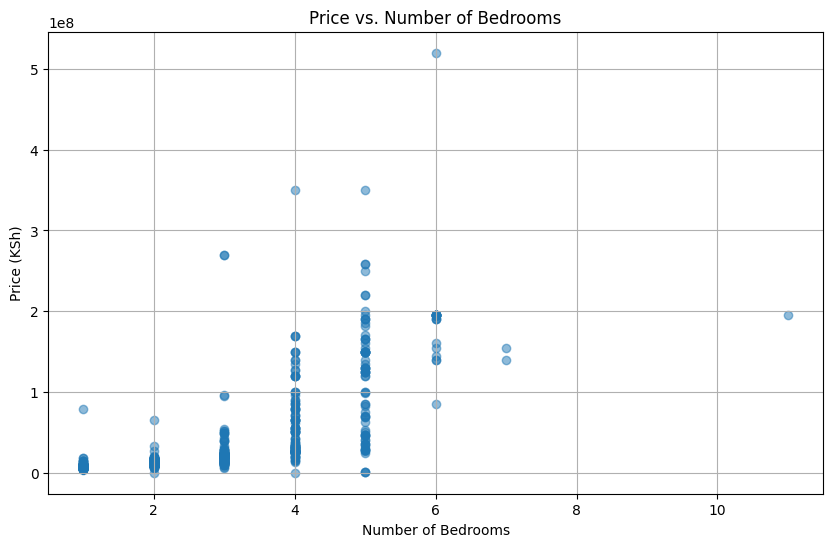

In [51]:
# Created scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(df['bedrooms'], df['price'], alpha=0.5)

# Added labels
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price (KSh)")
plt.title("Price vs. Number of Bedrooms")
plt.grid(True)
plt.show()

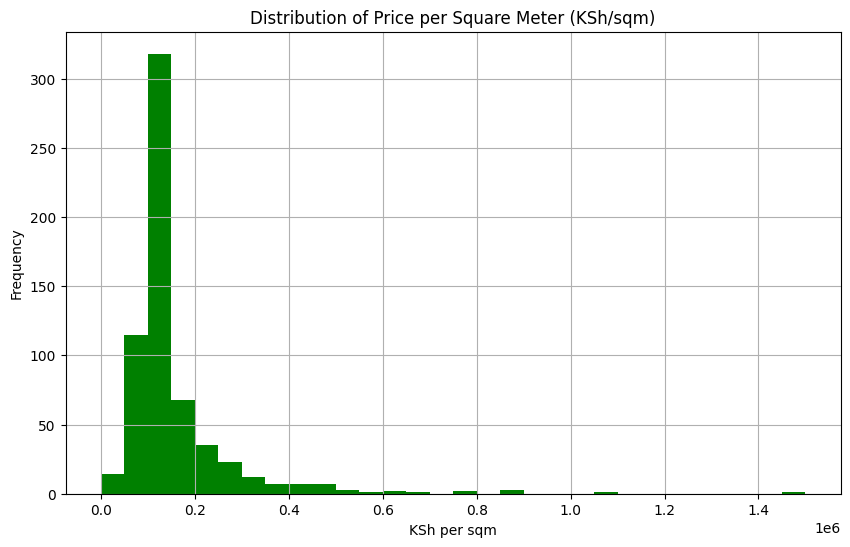

In [52]:
# New KPI
df['price_per_sqm'] = df['price'] / df['floor_size']


plt.figure(figsize=(10, 6))
df['price_per_sqm'].hist(bins=30, color='green')
plt.title("Distribution of Price per Square Meter (KSh/sqm)")
plt.xlabel("KSh per sqm")
plt.ylabel("Frequency")
plt.show()

In [53]:
# Checking which variables have the strongest relationship with 'price'
df.corr(numeric_only=True)['price'].sort_values(ascending=False)

price            1.00
price_per_sqm    0.73
bedrooms         0.69
bathrooms        0.65
floor_size       0.31
id              -0.03
Name: price, dtype: float64

In [54]:
df.to_csv('data_odyssey_lab_cleaned.csv', index=False)

print("Data successfully saved to CSV!")

Data successfully saved to CSV!


# **Smart Real Estate Platform: Exploratory Data Analysis**
**Data Odyssey Lab Submission**

---

## **Project Overview**
This notebook documents the data extraction, cleaning, and exploratory data analysis (EDA) phase for the Nairobi real estate market dataset. The objective is to transform raw property listings into a validated "Source of Truth" ready for business intelligence dashboarding.

## **Pipeline Summary**
1. **Data Cleaning:** Removed non-residential listings ("Vacant Land") and addressed placeholder floor size values (1.0 sqm).
2. **Deduplication:** Filtered out identical property entries to ensure accurate market volume.
3. **Feature Engineering:** Calculated the `price_per_sqm` KPI to standardize property value comparisons.
4. **Final Output:** Successfully distilled the raw data down to **676** clean, verified properties.